# 02 — Exploratory data analysis (10% user sample)

Ten questions; each answer feeds a later decision (definition of "liked", split dates, features).

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy.stats import chi2_contingency

sns.set_theme(style="whitegrid")
FIG = Path("../reports/figures")
FIG.mkdir(parents=True, exist_ok=True)

reviews = pd.read_parquet("../data/interim/reviews_sample.parquet")
items = pd.read_parquet("../data/interim/items_sample.parquet")
reviews["liked"] = reviews["rating"] >= 4
print(reviews.shape, items.shape)

(460834, 9) (60762, 9)


## Q1 — How are star ratings spread?

rating
1    0.127
2    0.054
3    0.073
4    0.134
5    0.612
Name: proportion, dtype: float64
liked (>=4): 74.6%   5-star only: 61.2%


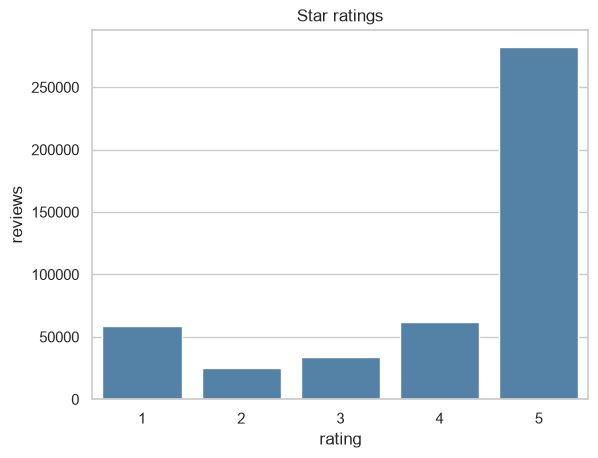

In [2]:
share = reviews["rating"].value_counts(normalize=True).sort_index()
print(share.round(3))
print(f"liked (>=4): {reviews['liked'].mean():.1%}   5-star only: {(reviews['rating'] == 5).mean():.1%}")

ax = sns.countplot(data=reviews, x="rating", color="steelblue")
ax.set(title="Star ratings", xlabel="rating", ylabel="reviews")
plt.savefig(FIG / "q1_ratings.png", dpi=120, bbox_inches="tight")
plt.show()

## Q2 / Q3 — Reviews per product and per user (log scale)

reviews per product: median 2, mean 7.6, max 1841, share with 1 review 43.4%, share with >=5 25.8%
reviews per user: median 1, mean 1.7, max 214, share with 1 review 72.2%, share with >=5 4.2%
top 1% of products get 28.8% of reviews


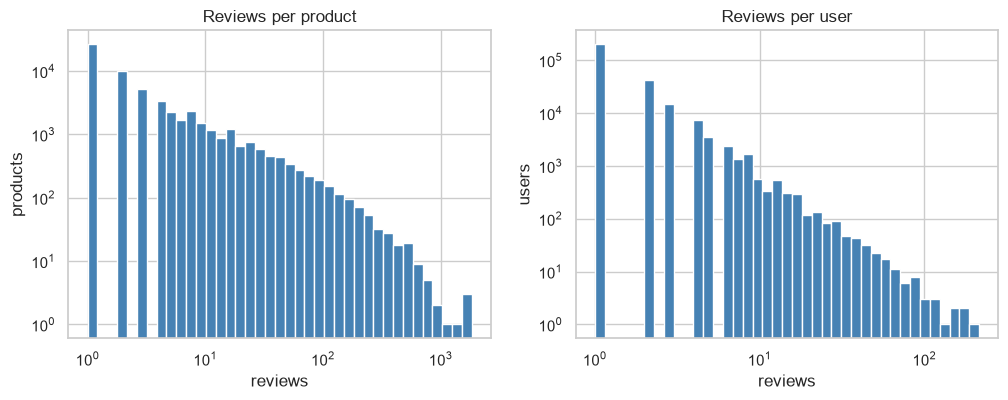

In [3]:
per_item = reviews.groupby("parent_asin").size()
per_user = reviews.groupby("user_id").size()

for name, s in [("product", per_item), ("user", per_user)]:
    print(f"reviews per {name}: median {s.median():.0f}, mean {s.mean():.1f}, max {s.max()}, "
          f"share with 1 review {(s == 1).mean():.1%}, share with >=5 {(s >= 5).mean():.1%}")

top_1pct = per_item.sort_values(ascending=False).head(max(1, len(per_item) // 100)).sum() / per_item.sum()
print(f"top 1% of products get {top_1pct:.1%} of reviews")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, s, name in [(axes[0], per_item, "product"), (axes[1], per_user, "user")]:
    bins = np.logspace(0, np.log10(s.max() + 1), 40)
    ax.hist(s, bins=bins, color="steelblue")
    ax.set(xscale="log", yscale="log", title=f"Reviews per {name}", xlabel="reviews", ylabel=f"{name}s")
plt.savefig(FIG / "q2_q3_long_tail.png", dpi=120, bbox_inches="tight")
plt.show()

## Q4 — How empty is the user × product table?

In [4]:
n_users, n_items = reviews["user_id"].nunique(), reviews["parent_asin"].nunique()
n_pairs = len(reviews[["user_id", "parent_asin"]].drop_duplicates())
density = n_pairs / (n_users * n_items)
print(f"{n_users:,} users x {n_items:,} products = {n_users * n_items:,} cells")
print(f"filled: {n_pairs:,}  density {density:.6%}  sparsity {1 - density:.4%}")
print(f"dense float32 matrix would need {n_users * n_items * 4 / 1e9:.0f} GB")
print(f"duplicate (user, product) reviews: {len(reviews) - n_pairs:,}")

276,666 users x 60,762 products = 16,810,779,492 cells
filled: 454,012  density 0.002701%  sparsity 99.9973%
dense float32 matrix would need 67 GB
duplicate (user, product) reviews: 6,822


## Q5 — How does activity change over time?

timestamp
2014    32111
2015    41272
2016    38905
2017    36612
2018    37696
2019    44331
2020    52215
2021    48064
2022    39829
2023    18110
Name: count, dtype: int64
share of reviews by calendar month:
{1: 0.125, 2: 0.091, 3: 0.097, 4: 0.078, 5: 0.072, 6: 0.069, 7: 0.077, 8: 0.074, 9: 0.066, 10: 0.069, 11: 0.075, 12: 0.108}
since 2018: 52.1% of reviews


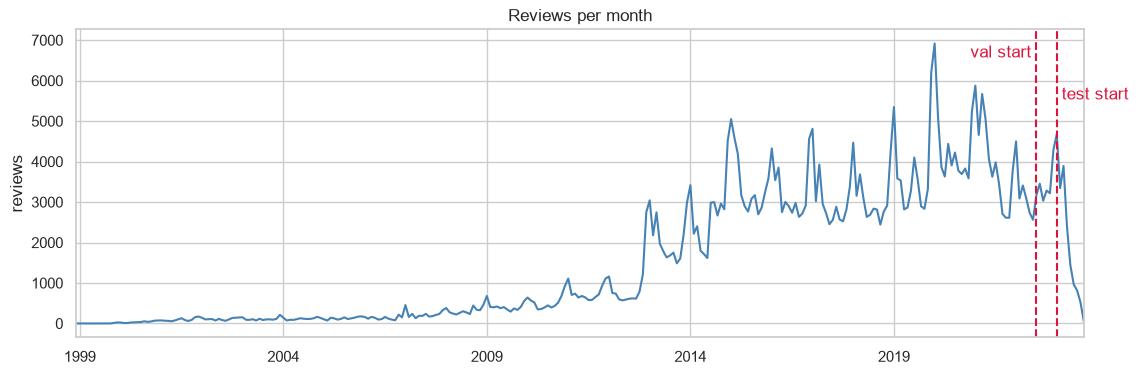

In [5]:
monthly = reviews.set_index("timestamp").resample("MS").size()
yearly = reviews["timestamp"].dt.year.value_counts().sort_index()
print(yearly.tail(10))
print("share of reviews by calendar month:")
print(reviews["timestamp"].dt.month.value_counts(normalize=True).sort_index().round(3).to_dict())
print(f"since 2018: {(reviews['timestamp'] >= '2018-01-01').mean():.1%} of reviews")

fig, ax = plt.subplots(figsize=(13, 4))
monthly.plot(ax=ax, color="steelblue")
for d, label, y in [("2022-07-01", "val start ", 0.95), ("2023-01-01", " test start", 0.80)]:
    ax.axvline(pd.Timestamp(d), color="crimson", ls="--")
    ax.text(pd.Timestamp(d), monthly.max() * y, label, color="crimson", ha="right" if "val" in label else "left")
ax.set(title="Reviews per month", xlabel="", ylabel="reviews")
plt.savefig(FIG / "q5_monthly.png", dpi=120, bbox_inches="tight")
plt.show()

In [6]:
train_end, val_end = pd.Timestamp("2022-07-01"), pd.Timestamp("2023-01-01")
split = pd.cut(reviews["timestamp"], [pd.Timestamp.min, train_end, val_end, pd.Timestamp.max],
               labels=["train", "val", "test"], right=False)
print(split.value_counts(normalize=True).round(3))

train_users = set(reviews.loc[split == "train", "user_id"])
test_users = reviews.loc[split == "test", "user_id"].unique()
print(f"test users already seen in train: {np.isin(test_users, list(train_users)).mean():.1%}")
print(f"test reviews written by returning users: {reviews.loc[split == 'test', 'user_id'].isin(train_users).mean():.1%}")

timestamp
train    0.916
val      0.044
test     0.039
Name: proportion, dtype: float64


test users already seen in train: 21.0%


test reviews written by returning users: 23.1%


## Q6 — What is missing?

`isna()` misses empty lists (`[]`) and empty strings, so both are counted as missing too.

In [7]:
def is_empty(v):
    if v is None or (isinstance(v, float) and np.isnan(v)):
        return True
    if isinstance(v, str):
        return v.strip() == ""
    return hasattr(v, "__len__") and len(v) == 0

missing = pd.DataFrame({
    "isna": items.isna().mean(),
    "isna_or_empty": items.map(is_empty).mean(),
}).sort_values("isna_or_empty", ascending=False)
print(missing.round(3))
print("\nreviews:")
print(reviews.map(is_empty).mean().round(4))

                 isna  isna_or_empty
price           0.469          0.469
description     0.000          0.357
features        0.000          0.223
categories      0.000          0.067
store           0.018          0.018
title           0.000          0.000
parent_asin     0.000          0.000
average_rating  0.000          0.000
rating_number   0.000          0.000

reviews:


user_id              0.0000
parent_asin          0.0000
rating               0.0000
title                0.0000
text                 0.0008
timestamp            0.0000
verified_purchase    0.0000
helpful_vote         0.0000
liked                0.0000
dtype: float64


## Q7 — Are there outliers?

count    32270.00
mean        48.84
std         90.16
min          0.00
25%         14.95
50%         25.99
75%         48.99
max       3499.99
Name: price, dtype: float64
price outliers (IQR): 9.3%   price <= $0.01: 32   price > $500: 152
user outliers (IQR): 6.8%   users with >=100 reviews: 10
max reviews by one user on one day: 78   user-days with >=10 reviews: 435


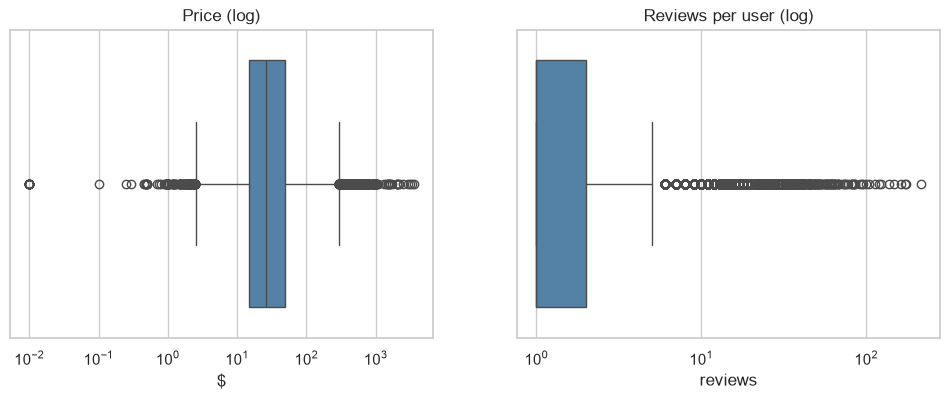

In [8]:
def iqr_outliers(s):
    q1, q3 = s.quantile([0.25, 0.75])
    return s > q3 + 1.5 * (q3 - q1)

price = items["price"].dropna()
print(price.describe().round(2))
print(f"price outliers (IQR): {iqr_outliers(price).mean():.1%}   price <= $0.01: {(price <= 0.01).sum()}   price > $500: {(price > 500).sum()}")
print(f"user outliers (IQR): {iqr_outliers(per_user).mean():.1%}   users with >=100 reviews: {(per_user >= 100).sum()}")

day = reviews["timestamp"].dt.floor("D")
per_user_day = reviews.groupby(["user_id", day]).size()
print(f"max reviews by one user on one day: {per_user_day.max()}   user-days with >=10 reviews: {(per_user_day >= 10).sum()}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.boxplot(x=price, ax=axes[0], color="steelblue", log_scale=True)
axes[0].set(title="Price (log)", xlabel="$")
sns.boxplot(x=per_user, ax=axes[1], color="steelblue", log_scale=True)
axes[1].set(title="Reviews per user (log)", xlabel="reviews")
plt.savefig(FIG / "q7_outliers.png", dpi=120, bbox_inches="tight")
plt.show()

## Q8 — Which numeric product features move together?

Counts are heavily skewed, so Pearson is computed on `log1p` values (Spearman shown for comparison).

Spearman:
                    price  average_rating  rating_number  sample_reviews  \
price                1.00            0.08           0.11            0.10   
average_rating       0.08            1.00           0.40            0.18   
rating_number        0.11            0.40           1.00            0.65   
sample_reviews       0.10            0.18           0.65            1.00   
sample_mean_rating   0.03            0.35          -0.02           -0.14   
helpful_votes        0.17            0.06           0.40            0.61   

                    sample_mean_rating  helpful_votes  
price                             0.03           0.17  
average_rating                    0.35           0.06  
rating_number                    -0.02           0.40  
sample_reviews                   -0.14           0.61  
sample_mean_rating                1.00          -0.17  
helpful_votes                    -0.17           1.00  


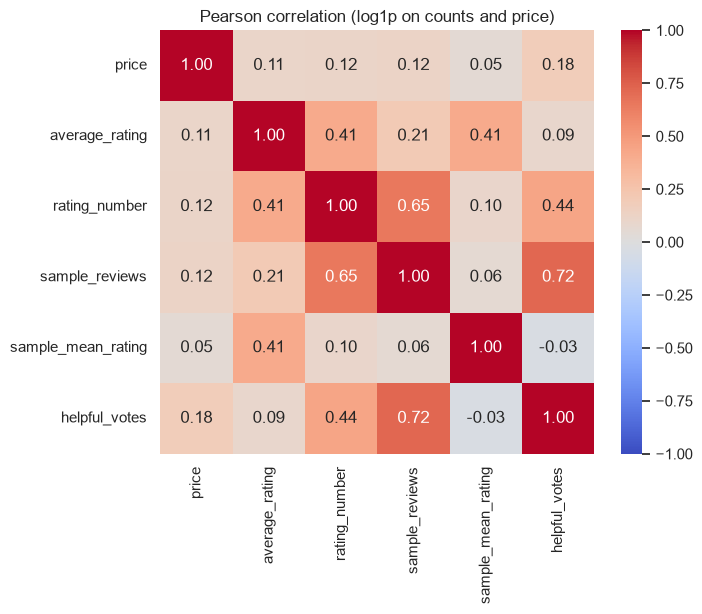

In [9]:
item_stats = reviews.groupby("parent_asin").agg(
    sample_reviews=("rating", "size"),
    sample_mean_rating=("rating", "mean"),
    helpful_votes=("helpful_vote", "sum"),
)
num = items.set_index("parent_asin")[["price", "average_rating", "rating_number"]].join(item_stats)

logged = num.copy()
for c in ["price", "rating_number", "sample_reviews", "helpful_votes"]:
    logged[c] = np.log1p(logged[c])

pearson = logged.corr(method="pearson")
print("Spearman:")
print(num.corr(method="spearman").round(2))

plt.figure(figsize=(7, 5.5))
sns.heatmap(pearson, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Pearson correlation (log1p on counts and price)")
plt.savefig(FIG / "q8_corr.png", dpi=120, bbox_inches="tight")
plt.show()

## Q9 — Is category related to high ratings?

Category = platform, the 2nd entry of `categories` (PC, PlayStation 4, Nintendo Switch, …). Top 10 kept, rest → Other.

chi2 = 3,450, dof = 10, p = 0.00e+00, Cramér's V = 0.087
                              mean    size
platform                                  
Xbox Series X & S            0.667    1737
Mac                          0.668    3513
PC                           0.702  121874
Xbox One                     0.709   42382
Unknown                      0.717   13766
PlayStation Digital Content  0.724    1670
PlayStation 4                0.744   43926
PlayStation 5                0.749    5239
Legacy Systems               0.771  167933
Other                        0.785   14539
Nintendo Switch              0.810   44255


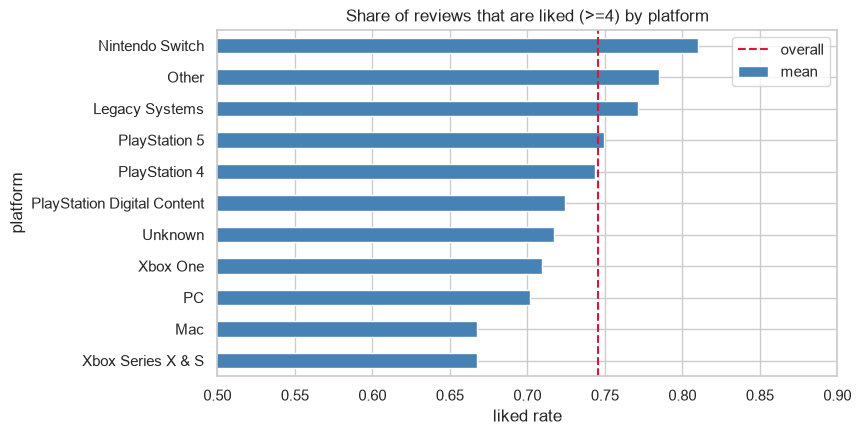

In [10]:
platform = items.set_index("parent_asin")["categories"].map(lambda c: c[1] if len(c) > 1 else "Unknown")
top = platform.value_counts().head(10).index
platform = platform.where(platform.isin(top), "Other")

rp = reviews[["parent_asin", "liked"]].join(platform.rename("platform"), on="parent_asin")
table = pd.crosstab(rp["platform"], rp["liked"])
chi2, p, dof, _ = chi2_contingency(table)
n = table.to_numpy().sum()
cramers_v = np.sqrt(chi2 / (n * (min(table.shape) - 1)))
print(f"chi2 = {chi2:,.0f}, dof = {dof}, p = {p:.2e}, Cramér's V = {cramers_v:.3f}")

liked_rate = rp.groupby("platform")["liked"].agg(["mean", "size"]).sort_values("mean")
print(liked_rate.round(3))

ax = liked_rate["mean"].plot.barh(color="steelblue", figsize=(8, 4.5))
ax.axvline(reviews["liked"].mean(), color="crimson", ls="--", label="overall")
ax.set(title="Share of reviews that are liked (>=4) by platform", xlabel="liked rate", xlim=(0.5, 0.9))
ax.legend()
plt.savefig(FIG / "q9_platform.png", dpi=120, bbox_inches="tight")
plt.show()

## Q10 — Do verified buyers rate differently?

verified share: 86.3%
                    mean    size
verified_purchase               
False              3.731   62942
True               4.099  397892
verified_purchase
False    0.660
True     0.759
Name: liked, dtype: float64
chi2 (verified x rating) = 4,877, p = 0.00e+00


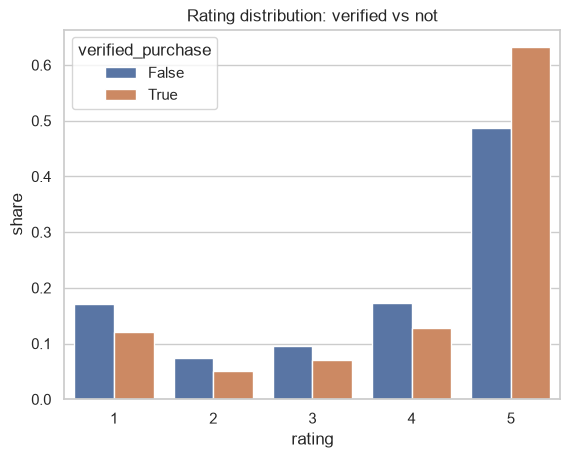

In [11]:
print(f"verified share: {reviews['verified_purchase'].mean():.1%}")
print(reviews.groupby("verified_purchase")["rating"].agg(["mean", "size"]).round(3))
print(reviews.groupby("verified_purchase")["liked"].mean().round(3))
chi2, p, _, _ = chi2_contingency(pd.crosstab(reviews["verified_purchase"], reviews["rating"]))
print(f"chi2 (verified x rating) = {chi2:,.0f}, p = {p:.2e}")

dist = (reviews.groupby("verified_purchase")["rating"].value_counts(normalize=True)
        .rename("share").reset_index())
ax = sns.barplot(data=dist, x="rating", y="share", hue="verified_purchase")
ax.set(title="Rating distribution: verified vs not")
plt.savefig(FIG / "q10_verified.png", dpi=120, bbox_inches="tight")
plt.show()

## Key findings

- **Ratings are very positive.** 61.2% of reviews are 5★ and 74.6% are ≥4★. "Liked" = rating ≥ 4. A model that always says "liked" is already 74.6% accurate, so accuracy is useless — use ranking metrics (Recall@K, NDCG@K).
- **Strong popularity bias.** The top 1% of products receive 28.8% of reviews, while 43.4% of products have a single review. A most-popular baseline will be hard to beat, and tail items need content features.
- **Most users are one-off.** 72.2% of users wrote one review and only 4.2% wrote ≥5. Only 21.0% of test-period users appear in train, so cold start is the main problem, not a corner case.
- **The user × product table is 99.9973% empty** (density 0.0027%). Dense storage would need 67 GB, so use `scipy.sparse`. 6,822 duplicate (user, product) pairs must be deduplicated.
- **Time split: train < 2022-07-01, val 2022-07-01 → 2022-12-31, test ≥ 2023-01-01** (91.6% / 4.4% / 3.9%). Activity peaks in 2020; December + January hold 23.3% of reviews; 2023 tails off because collection ended in Sept 2023.
- **Product metadata has gaps.** Price is missing for 46.9% of products, description is empty for 35.7%, features for 22.3%, categories for 6.7%, store for 1.8%. Empty lists hide from `isna()`. Plan: impute price by platform median + a `price_missing` flag; fall back to title for text.
- **Outliers exist.** Prices run up to $3,499.99 with 32 items at ≤ $0.01; one user posted 78 reviews in a single day and 435 user-days have ≥10 reviews (bot-like). Plan: clip/log price, flag burst users. Price is nearly uncorrelated with everything (Spearman ≤ 0.17), while review count and helpful votes overlap (0.61–0.65) — keep one popularity count.
- **Category and verified status matter, but weakly.** Platform vs liked: χ² p < 0.001 but Cramér's V = 0.087 (Switch 81.0% liked vs PC 70.2%). Verified buyers (86.3% of reviews) like 75.9% vs 66.0% for unverified (mean 4.10 vs 3.73). Keep both as features; don't filter out unverified reviews.